Loaded 9 GLM pkls
Pooled shape: (54, 12)

--- Statistics for Predictive Gain (Full - Ablated) ---
  d2         | Mean: 0.00666 | Median: 0.00353 | p-val (vs 0): 3.906e-03
  MUA        | Mean: 0.00079 | Median: 0.00034 | p-val (vs 0): 3.711e-02
  FR_std     | Mean: 0.00069 | Median: 0.00018 | p-val (vs 0): 2.129e-01


C:\Users\Cornell\AppData\Local\Temp\ipykernel_25692\3437889748.py:108: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


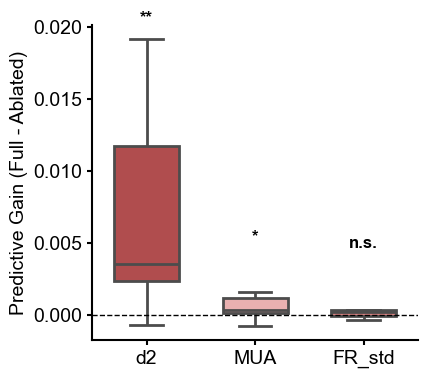

Saved: None

--- Comparative Statistics (Kruskal-Wallis) ---
Kruskal-Wallis Test (Are features different?): H=8.00, p=0.0183
  -> Significant difference between features.

PAIRWISE COMPARISONS (Importance_AUC)
Comparison                | Winner     | Diff     | P-adj      | Sig | n
--------------------------------------------------------------------------------
d2 vs MUA                 | d2         | 0.0059   | 3.52e-02 | *   | 9
d2 vs FR_std              | d2         | 0.0060   | 3.91e-02 | *   | 9
MUA vs FR_std             | MUA        | 0.0001   | 9.10e-01 | ns  | 9


In [9]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy import stats
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ---------------------------
# Settings
# ---------------------------
indir  = r"D:\Documents\GitHub\Sleep_criticaltiy\data\GLM_mice\explore"
outdir = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main"
os.makedirs(outdir, exist_ok=True)

FEATURES_KEEP = ["d2", "MUA", "FR_std"]  # add EI_ratio etc. if saved
# ---------------------------
# Helpers
# ---------------------------
def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

def parse_animal_day_from_filename(fp):
    base = os.path.basename(fp)
    m = re.match(r"(.+?)_(.+?)_ablation_results_GLM\.pkl$", base)
    return (m.group(1), m.group(2)) if m else (None, None)

def extract_ablation_feature(model_name):
    s = model_name.replace("Ablate ", "")
    if "_z" in s:
        return s.split("_z")[0]
    return s

def get_star_string(p):
    """Returns significance stars based on p-value."""
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'n.s.'

# ---------------------------
# PLOTTING FUNCTION
# ---------------------------
def make_boxplot_matplotlib(df, value_col, title, ylabel, save_path, order=None, show_points=True):
    """
    Standard matplotlib boxplot with Wilcoxon Signed-Rank Test annotations.
    """
    if order is None:
        order = sorted(df["Feature"].unique())

    # Prepare data list for boxplot
    data_list = []
    for f in order:
        vals = df.loc[df["Feature"] == f, value_col].dropna().values
        data_list.append(vals)
    long_df = pd.DataFrame({
    "value": np.concatenate(data_list),
    "epoch": np.repeat(order, [len(x) for x in data_list])
    })

    long_df["epoch"] = pd.Categorical(long_df["epoch"], categories=order, ordered=True)

    fig, ax = plt.subplots(figsize=(4.5, 4)) # Slightly wider for stats text
    palette = {
        "d2": "#c03d3eff",        # blue  
        "MUA": "#f3a6a6ff",       # orange
        "FR_std": "#e57373ff"     # green }
    }
    # Draw boxplot
    sns.boxplot(
        data=long_df,
        x="epoch",
        y="value",
        order=order,
        ax=ax,
        width=0.6,
        showfliers=False,
        palette=palette,   # optional: colors
        linewidth=2
    )


    # -------------------------------------------------------
    # STATISTICS & ANNOTATION
    # -------------------------------------------------------
    print(f"\n--- Statistics for {ylabel} ---")
    y_max_limit = -np.inf
    xticks = ax.get_xticks()  
    for i, (feature, vals) in enumerate(zip(order, data_list), start=1):
        if len(vals) < 2:
            print(f"  {feature}: Not enough data for test (n={len(vals)})")
            continue
        
        # Test: Is the distribution significantly greater than 0?
        # Wilcoxon Signed-Rank Test is appropriate for "paired" diffs (Full - Reduced)
        try:
            stat, pval = stats.wilcoxon(vals, alternative='greater')
        except ValueError:
            # Fallback if all values are identical (e.g. all 0)
            pval = 1.0

        print(f"  {feature:10s} | Mean: {np.mean(vals):.5f} | Median: {np.median(vals):.5f} | p-val (vs 0): {pval:.3e}")

        # Add stars to plot
        stars = get_star_string(pval)
        
        # Calculate position for the star (above the highest point or whisker)
        if len(vals) > 0:
            top_val = np.max(vals)
            # Add a small buffer based on data range
            y_range = (np.max(np.concatenate(data_list)) - np.min(np.concatenate(data_list)))
            text_y = top_val + (y_range * 0.05)
            
            # actual x positions used by the plot
            x = xticks[i-1]           # because the loop index i starts at 1

            ax.text(x, text_y, stars, ha="center", va="bottom",
                    fontsize=12, fontweight="bold")
                        
            # Track max y for axis scaling
            if text_y > y_max_limit:
                y_max_limit = text_y

    # Adjust Y-axis to fit stars
    current_ylim = ax.get_ylim()
    if y_max_limit > current_ylim[1]:
        ax.set_ylim(current_ylim[0], y_max_limit + (y_max_limit * 0.05))

    ax.axhline(0, linestyle="--", linewidth=1, color="k")
    ax.set_title(title if title else "")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
    _despine(ax)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")

# ---------------------------
# Load + pool
# ---------------------------
def load_and_pool_glm_pickles(indir):
    files = sorted(glob.glob(os.path.join(indir, "*_ablation_results_GLM.pkl")))
    if len(files) == 0:
        raise FileNotFoundError(f"No *_ablation_results_GLM.pkl found in: {indir}")

    all_rows = []
    for fp in files:
        obj = pd.read_pickle(fp)
        if not isinstance(obj, dict) or "summary" not in obj:
            continue

        df = obj["summary"].copy()
        df["file"] = os.path.basename(fp)
        
        # Metadata extraction
        animal = obj.get("animal", None)
        day = obj.get("day", None)
        if animal is None or day is None:
            animal2, day2 = parse_animal_day_from_filename(fp)
            animal = animal if animal is not None else animal2
            day = day if day is not None else day2

        df["animal"] = animal
        df["day"] = day
        df["n_samples"] = obj.get("n_samples", np.nan)
        all_rows.append(df)

    pooled = pd.concat(all_rows, ignore_index=True)

    # Process Data
    ab = pooled[pooled["Model"].str.startswith("Ablate")].copy()
    ab["Feature"] = ab["Model"].apply(extract_ablation_feature)
    ab = ab[ab["Feature"].isin(FEATURES_KEEP)].copy()
    
    # Calculate Importance Metrics
    # (Positive value = Interaction helped)
    ab["Importance_AUC"] = -ab["ΔAUC_vs_Full"]
    ab["Importance_LL"]  =  ab["ΔLogLoss_vs_Full"]

    gain = pooled[pooled["Model"].isin(["Reduced (main effects)", "Full (main + interactions)", "Gain (Full - Reduced)"])].copy()

    return pooled, ab, gain, files

# ---------------------------
# MAIN EXECUTION
# ---------------------------
pooled, ab_df, gain_df, glm_files = load_and_pool_glm_pickles(indir)

print(f"Loaded {len(glm_files)} GLM pkls")
print("Pooled shape:", pooled.shape)

# 1. Boxplot + Stats for AUC Importance
make_boxplot_matplotlib(
    ab_df,
    value_col="Importance_AUC",
    title=None,
    ylabel="Predictive Gain (Full - Ablated)",
    save_path=None,
    order=[f for f in FEATURES_KEEP if f in ab_df["Feature"].unique()],
    show_points=True
)


# 3. Overall ANOVA (Kruskal-Wallis) to see if features differ from each other
print("\n--- Comparative Statistics (Kruskal-Wallis) ---")
try:
    groups = []
    group_names = []
    for f in FEATURES_KEEP:
        if f in ab_df["Feature"].unique():
            vals = ab_df.loc[ab_df["Feature"] == f, "Importance_AUC"].dropna().values
            groups.append(vals)
            group_names.append(f)
    
    if len(groups) > 1:
        stat, pval = stats.kruskal(*groups)
        print(f"Kruskal-Wallis Test (Are features different?): H={stat:.2f}, p={pval:.4f}")
        if pval < 0.05:
            print("  -> Significant difference between features.")
    else:
        print("Not enough groups for Kruskal-Wallis.")
except Exception as e:
    print(f"Error in comparative stats: {e}")
    import itertools

import itertools

import itertools
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

def perform_pairwise_comparisons(df, value_col, features, correction="holm"):
    """
    Pairwise Wilcoxon signed-rank tests between features (paired by 'file').
    Includes multiple-comparison correction across all pairs.
    
    correction: "holm" (FWER) or "fdr_bh" (FDR) or None
    """
    print(f"\n{'='*20}\nPAIRWISE COMPARISONS ({value_col})\n{'='*20}")

    pivoted = df.pivot(index='file', columns='Feature', values=value_col)
    pairs = list(itertools.combinations(features, 2))

    results = []
    for f1, f2 in pairs:
        subset = pivoted[[f1, f2]].dropna()
        n = len(subset)
        if n < 2:
            continue

        stat, pval = stats.wilcoxon(subset[f1], subset[f2])
        mean_diff = subset[f1].mean() - subset[f2].mean()
        winner = f1 if mean_diff > 0 else f2

        results.append({
            "Comparison": f"{f1} vs {f2}",
            "f1": f1, "f2": f2,
            "Winner": winner,
            "Mean_Diff": abs(mean_diff),
            "p_value": float(pval),
            "n": int(n)
        })

    res_df = pd.DataFrame(results).sort_values("p_value")
    if res_df.empty:
        print("No valid paired comparisons.")
        return res_df

    # Multiple-comparison correction across all pairwise tests
    if correction is not None:
        reject, p_adj, _, _ = multipletests(res_df["p_value"].to_numpy(), method=correction)
        res_df["p_adj"] = p_adj
        res_df["reject"] = reject
        p_for_sig = res_df["p_adj"]
        p_label = "P-adj"
    else:
        p_for_sig = res_df["p_value"]
        p_label = "P"

    # Display
    print(f"{'Comparison':<25} | {'Winner':<10} | {'Diff':<8} | {p_label:<10} | {'Sig'} | n")
    print("-" * 80)
    for _, row in res_df.iterrows():
        p = float(p_for_sig.loc[row.name])
        sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
        print(f"{row['Comparison']:<25} | {row['Winner']:<10} | {row['Mean_Diff']:.4f}   | {p:.2e} | {sig:<3} | {row['n']}")

    return res_df

# --- EXECUTE ---
# Run on the AUC importance data
pairwise_stats = perform_pairwise_comparisons(ab_df, "Importance_AUC", FEATURES_KEEP)


--- Statistics for Predictive Gain (Full - Ablated) ---
  FR_std     | Mean: 1.00000 | Median: 0.26468 | p-val (vs 0): 2.129e-01
  MUA        | Mean: 1.14258 | Median: 0.49030 | p-val (vs 0): 3.711e-02
  d2         | Mean: 9.66512 | Median: 5.11915 | p-val (vs 0): 3.906e-03


C:\Users\Cornell\AppData\Local\Temp\ipykernel_25692\3437889748.py:108: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


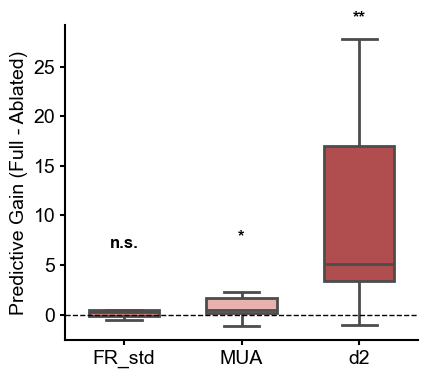

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\FigF_GLM_boxplot_interaction_importance_AUC_normalized.svg

PAIRWISE COMPARISONS (Importance_AUC_normalized)
Comparison                | Winner     | Diff     | P-adj      | Sig | n
--------------------------------------------------------------------------------
MUA vs d2                 | d2         | 8.5225   | 3.52e-02 | *   | 9
FR_std vs d2              | d2         | 8.6651   | 3.91e-02 | *   | 9
FR_std vs MUA             | MUA        | 0.1426   | 9.10e-01 | ns  | 9


In [10]:
# Add normalized version (divide by mean of FR_std importance)
ab_df_norm = ab_df.copy()

# Calculate mean FR_std importance across all sessions
fr_std_mean = ab_df[ab_df["Feature"] == "FR_std"]["Importance_AUC"].mean()

# Normalize all features by dividing by this mean
ab_df_norm["Importance_AUC_normalized"] = ab_df_norm["Importance_AUC"] / fr_std_mean

# Define plot order: FR_std, MUA, d2
plot_order = ["FR_std", "MUA", "d2"]

# Plot normalized version
make_boxplot_matplotlib(
    ab_df_norm,
    value_col="Importance_AUC_normalized",
    title=None,
    ylabel="Predictive Gain (Full - Ablated)",
    save_path=os.path.join(outdir, "FigF_GLM_boxplot_interaction_importance_AUC_normalized.svg"),
    order=[f for f in plot_order if f in ab_df_norm["Feature"].unique()],
    show_points=True
)

# Pairwise comparisons on normalized values
pairwise_stats_norm = perform_pairwise_comparisons(ab_df_norm, "Importance_AUC_normalized", plot_order)